# Axe 9 : le graphe des départements qui « souffrent ensemble »

Même démarche que pour les secteurs (axe 8, `graphe_secteurs.ipynb`), appliquée aux **départements** : deux départements sont proches si leurs défaillances **évoluent de la même façon** dans le temps. La question en plus : les groupes de départements qui se forment sont-ils **géographiques** (des départements voisins), ou pas ?

Le code commun est dans `scripts/graphe_utils.py`. Les contours des départements viennent d'un GeoJSON public simplifié (projet *france-geojson*), enregistré dans `data/raw/geo/` : il ne contient que la métropole, les départements d'outre-mer apparaissent dans les tableaux mais pas sur les cartes.

### Les décisions

On reprend les choix de l'axe 8, qui valent aussi ici :

| Sujet | Décision | Qui |
|---|---|---|
| Préparation des courbes | **Évolution sur 12 mois glissants**, comme pour les secteurs. | Luka (axe 8) |
| Petits départements | On enlève ceux avec **moins de 500 défaillances** au total, comme pour les secteurs : Saint-Pierre-et-Miquelon (975), l'ancien code de Mayotte (985) et Mayotte (976). On garde 100 départements. | Luka |
| Coefficient de similarité | **Spearman**, comme pour les secteurs (plus robuste aux extrêmes du Covid). La section 3 vérifie que le problème est le même. | Luka |
| Seuil | **0,67**, donné par la méthode du coude (section 4). | Luka |
| Nombre de communautés | Règle en 3 étapes sur 50 graines (section 8) : la résolution γ qui maximise la modularité moyenne, le nombre de communautés le plus fréquent à ce γ, et parmi ces graines le découpage de meilleure modularité. | Luka |

## 1. Chargement

In [1]:
import sys
sys.path.append("../../scripts")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import modularity
from data_utils import PROCESSED, RAW
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
pd.set_option("display.max_rows", 110)

series = pd.read_parquet(DASH / "series_departements_mois.parquet").loc["2008-01":"2026-10"]
total = series.sum().sort_values()
noms, polys = gu.charger_departements(RAW / "geo" / "departements.geojson")
nom = lambda d: noms.get(d, d)
print(series.shape, "(mois × départements)")
total.head(6).rename(index=nom).to_frame("défaillances (2008-2026)")

(226, 103) (mois × départements)


,défaillances (2008-2026)
departement,
985,2.0
975,39.0
Mayotte,298.0
Lozère,757.0
Creuse,1428.0
Guyane,1491.0


## 2. Préparation des courbes

In [2]:
MIN_DEFAILLANCES = 500
gardes = total[total >= MIN_DEFAILLANCES].index
evolution = gu.evolution_12_mois(series[gardes])
print("départements gardés :", len(gardes), "| mois :", evolution.index[0], "→", evolution.index[-1])
(100 * evolution[["75", "13", "69", "59", "33", "971"]].iloc[::24]).round(0).rename(columns=nom)

départements gardés : 100 | mois : 2009-12 → 2026-10


departement,Paris,Bouches-du-Rhône,Rhône,Nord,Gironde,Guadeloupe
mois,,,,,,
2009-12,4.0,21.0,30.0,14.0,3.0,-17.0
2011-12,-10.0,-2.0,-3.0,-4.0,-10.0,9.0
2013-12,11.0,9.0,2.0,3.0,10.0,26.0
2015-12,7.0,-6.0,-6.0,-2.0,-3.0,-22.0
2017-12,-9.0,-2.0,-3.0,-7.0,-9.0,-4.0
2019-12,-4.0,4.0,-1.0,-6.0,9.0,-11.0
2021-12,-12.0,4.0,-11.0,-10.0,-14.0,-4.0
2023-12,36.0,42.0,43.0,31.0,50.0,21.0
2025-12,14.0,-8.0,6.0,-1.0,3.0,42.0


## 3. Pearson ou Spearman, et l'effet du Covid

In [3]:
pearson, spearman = evolution.corr(), evolution.corr(method="spearman")
periodes = {
    "toute la période": evolution,
    "sans 2020-2024": evolution[(evolution.index < "2020-01") | (evolution.index > "2024-12")],
}
pd.DataFrame({
    p: {"Pearson médian": gu.triangle(e.corr()).median(),
        "Spearman médian": gu.triangle(e.corr("spearman")).median(),
        "écart moyen (Pearson - Spearman)": (gu.triangle(e.corr()) - gu.triangle(e.corr("spearman"))).mean()}
    for p, e in periodes.items()
}).T.round(3)

,Pearson médian,Spearman médian,écart moyen (Pearson - Spearman)
toute la période,0.679,0.550,0.117
sans 2020-2024,0.144,0.133,0.012


### Observations

- On retrouve exactement la situation des secteurs : **Pearson est au-dessus de Spearman** (+0,12 en moyenne), et sans 2020-2024 l'écart disparaît (+0,01).
- Sans le Covid, les départements ne se ressemblent presque plus (Spearman médian 0,13 au lieu de 0,55). Le graphe décrit donc surtout **comment les départements ont vécu la crise et le rattrapage**.

## 4. Choisir le seuil (méthode du coude, sur Spearman)

coudes : {'nœuds gardés': 0.67, 'arêtes': 0.7}


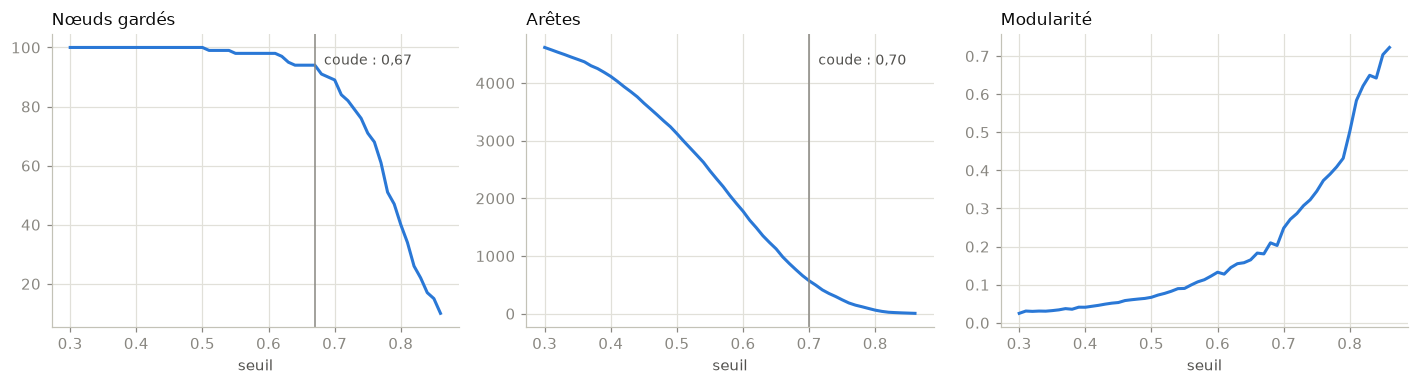

,nœuds gardés,arêtes,composantes,communautés,modularité
seuil,,,,,
0.62,97,1491,1,5,0.145
0.63,95,1351,1,5,0.155
0.64,94,1234,1,5,0.158
0.65,94,1124,1,5,0.165
0.66,94,984,1,4,0.183
0.67,94,869,1,7,0.181
0.68,91,762,2,6,0.210
0.69,90,659,2,6,0.203
0.70,89,570,3,9,0.248


In [4]:
S = spearman
courbes = gu.courbe_seuils(S, np.round(np.arange(0.30, 0.861, 0.01), 2))
coudes = {m: gu.coude(courbes.index, courbes[m]) for m in ["nœuds gardés", "arêtes"]}
print("coudes :", coudes)
gu.tracer_coudes(courbes, coudes)
courbes.loc[coudes["nœuds gardés"] - 0.05:coudes["arêtes"] + 0.05].round(3)

### Observations

- Les coudes tombent à **0,67** (départements gardés) et **0,70** (arêtes). On prend le coude des nœuds gardés, comme pour les secteurs : **0,67**.

## 5. Le graphe retenu (seuil 0,67)

In [5]:
SEUIL = 0.67
G = gu.construire_graphe(S, SEUIL)
isoles = [d for d in S.index if d not in G]
print(G, "| composantes :", nx.number_connected_components(G), "| densité :", round(nx.density(G), 3))
pd.DataFrame({"département": [nom(d) for d in isoles], "défaillances": [int(total[d]) for d in isoles],
              "meilleure similarité": [S[d].drop(d).max() for d in isoles]}, index=isoles
            ).sort_values("meilleure similarité", ascending=False).round(3)

Graph with 94 nodes and 869 edges | composantes : 1 | densité : 0.199


,département,défaillances,meilleure similarité
23,Creuse,1428,0.635
48,Lozère,757,0.626
02,Aisne,6816,0.621
55,Meuse,2216,0.614
974,La Réunion,11952,0.541
973,Guyane,1491,0.503


### Observations

- Le graphe garde **94 départements** et **869 arêtes**, en un seul morceau (densité 0,20).
- **6 départements** sont isolés : la Creuse, la Lozère, l'Aisne, la Meuse, et deux départements d'outre-mer, **La Réunion** et la **Guyane**, qui évoluent nettement à part (meilleure similarité 0,54 et 0,50).

## 6. Est-ce un réseau « small world » ?

In [6]:
tableau, sigma = gu.small_world(G)
print("sigma =", round(sigma, 2))
tableau.round(3)

sigma = 2.09


,notre graphe,graphes aléatoires (20)
clustering moyen,0.490,0.200
plus court chemin moyen,2.133,1.821
diamètre,5.000,3.000


### Observations

- Clustering moyen **0,49** contre **0,20** pour des graphes aléatoires, pour des chemins à peine plus longs (2,13 contre 1,82) : **σ = 2,09**, le graphe est **small world**.

## 7. Les départements centraux, et le rôle de la géographie

En plus des centralités, on regarde si les arêtes du graphe relient surtout des **départements voisins** (qui ont une frontière commune). On compare avec le hasard : la part de paires voisines parmi **toutes** les paires possibles de départements de métropole.

In [7]:
cent = gu.centralites(G)
cent.insert(0, "département", [nom(d) for d in cent.index])
cent["défaillances"] = [int(total[d]) for d in cent.index]
cent.sort_values("degré", ascending=False).head(10).round(3)

,département,degré,intermédiarité,pagerank,défaillances
42,Loire,50,0.036,0.025,12264
64,Pyrénées-Atlantiques,43,0.083,0.023,9098
59,Nord,43,0.058,0.023,37675
76,Seine-Maritime,42,0.056,0.022,15933
33,Gironde,41,0.023,0.021,26955
62,Pas-de-Calais,41,0.027,0.021,17683
49,Maine-et-Loire,40,0.023,0.020,9622
69,Rhône,40,0.022,0.020,31071
56,Morbihan,40,0.022,0.020,10585
17,Charente-Maritime,40,0.019,0.020,9824


In [8]:
cent[["degré", "intermédiarité", "pagerank", "défaillances"]].corr(method="spearman").round(2)

,degré,intermédiarité,pagerank,défaillances
degré,1.00,0.79,0.99,0.42
intermédiarité,0.79,1.00,0.85,0.47
pagerank,0.99,0.85,1.00,0.46
défaillances,0.42,0.47,0.46,1.00


### Observations

- Le département le plus relié est la **Loire** (50 voisins), devant les Pyrénées-Atlantiques, le Nord et la Seine-Maritime. Les Pyrénées-Atlantiques sont aussi le principal « pont » (intermédiarité 0,083).
- Contrairement aux secteurs, la centralité est **peu liée à la taille** (Spearman 0,42 à 0,47 avec le nombre de défaillances) : Paris n'est pas dans les 10 plus reliés.

In [9]:
voisins = gu.voisins_geographiques(polys)
est_voisin = lambda a, b: (a, b) in voisins or (b, a) in voisins
metro = [d for d in G if d in polys]
aretes_metro = [(u, v) for u, v in G.edges() if u in polys and v in polys]
paires_metro = len(metro) * (len(metro) - 1) / 2
print(f"arêtes entre départements voisins : {np.mean([est_voisin(u, v) for u, v in aretes_metro]):.1%}"
      f" | parmi toutes les paires possibles : {sum(est_voisin(a, b) for a, b in voisins if a in metro and b in metro) / paires_metro:.1%}")

arêtes entre départements voisins : 8.0% | parmi toutes les paires possibles : 5.2%


### Observations

- Seulement **8 %** des arêtes relient deux départements **voisins**, contre **5,2 %** si les arêtes étaient placées au hasard. La proximité géographique joue un **petit** rôle : deux départements voisins ont un peu plus de chances d'évoluer pareil, mais la plupart des liens relient des départements éloignés.

## 8. Les communautés (Louvain) : combien en garder ?

Avec Louvain, on ne fixe pas le nombre de communautés : l'algorithme le trouve en maximisant la **modularité**. Le seul réglage est la **résolution γ** (plus γ est haut, plus il fait de petits groupes). Et Louvain n'est pas déterministe : le résultat change avec la graine aléatoire.

On choisit donc avec une **règle en 3 étapes**, appliquée sur 50 graines pour chaque γ :
1. **γ** = celui qui donne la **meilleure modularité moyenne** ;
2. **nombre de communautés** = celui qui revient **le plus souvent** à ce γ ;
3. parmi les graines qui donnent ce nombre, on garde le **découpage de meilleure modularité**.

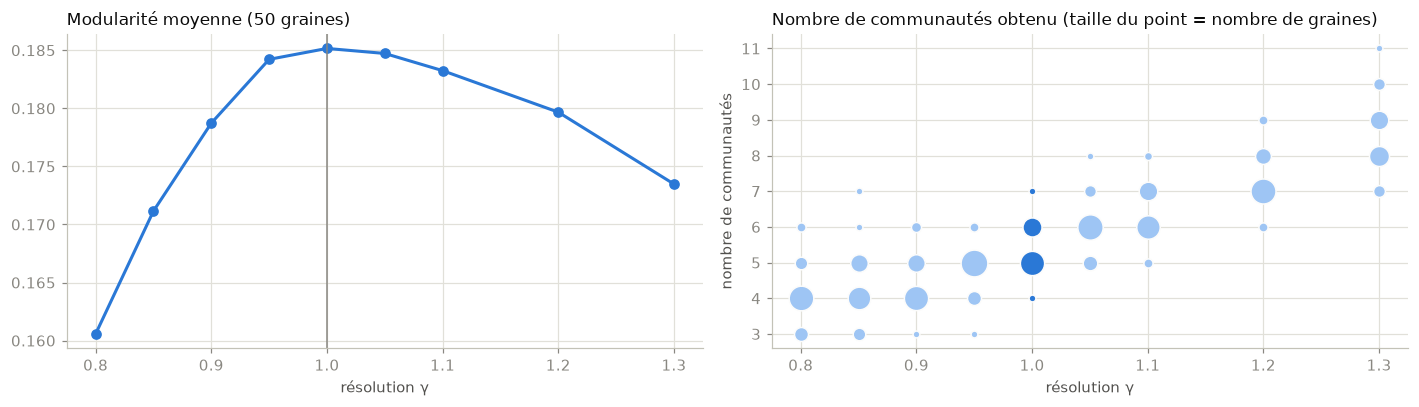

règle : γ = 1.0 | 5 communautés | modularité du découpage retenu : 0.191


,modularité moyenne,nombre le plus fréquent,part des graines avec ce nombre,répartition du nombre,ARI moyen entre graines
résolution,,,,,
0.80,0.161,4,0.62,"{3: 9, 4: 31, 5: 7, 6: 3}",0.461
0.85,0.171,4,0.52,"{3: 7, 4: 26, 5: 15, 6: 1, 7: 1}",0.398
0.90,0.179,4,0.60,"{3: 1, 4: 30, 5: 15, 6: 4}",0.394
0.95,0.184,5,0.74,"{3: 1, 4: 9, 5: 37, 6: 3}",0.385
1.00,0.185,5,0.60,"{4: 1, 5: 30, 6: 18, 7: 1}",0.470
1.05,0.185,6,0.66,"{5: 10, 6: 33, 7: 6, 8: 1}",0.497
1.10,0.183,6,0.56,"{5: 3, 6: 28, 7: 17, 8: 2}",0.532
1.20,0.180,7,0.64,"{6: 3, 7: 32, 8: 12, 9: 3}",0.579
1.30,0.173,8,0.40,"{7: 6, 8: 20, 9: 17, 10: 6, 11: 1}",0.578


In [10]:
tableau_gamma, partitions = gu.balayage_resolution(G, [0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.3])
gamma, nombre, communautes, communaute, q = gu.regle_communautes(tableau_gamma, partitions)
gu.tracer_balayage(tableau_gamma, gamma)
print(f"règle : γ = {gamma} | {nombre} communautés | modularité du découpage retenu : {q:.3f}")
tableau_gamma.round(3)

### Observations

- La modularité moyenne forme un **plateau** de γ = 0,95 à 1,05 (0,184 à 0,185), le maximum étant à γ = 1. Elle reste **sous 0,3** : la structure est **peu marquée**, comme pour les secteurs.
- À γ = 1, Louvain trouve **5 communautés** dans 30 graines sur 50 (6 dans 18 graines). La règle retient donc **5 communautés**, avec le découpage de meilleure modularité (**0,191**).
- Les découpages changent beaucoup selon la graine (ARI 0,47) : à lire comme des tendances.

In [11]:
# Le découpage retenu par la règle
cent["communauté"] = pd.Series(communaute)
print(f"{len(communautes)} communautés, modularité {q:.3f}")
for i, c in enumerate(communautes, 1):
    top = sorted(c, key=lambda d: -total[d])
    print(f"\n{i}. ({len(c)} départements) " + " · ".join(nom(d) for d in top))

5 communautés, modularité 0.191

1. (25 départements) Rhône · Var · Hauts-de-Seine · Haute-Garonne · Bas-Rhin · Val-d'Oise · Yvelines · Ille-et-Vilaine · Haute-Savoie · Vaucluse · Morbihan · Calvados · Meurthe-et-Moselle · Eure · Manche · Charente · Deux-Sèvres · Aube · Jura · Ardennes · Orne · Haute-Saône · Nièvre · Gers · Lot

2. (23 départements) Bouches-du-Rhône · Gironde · Isère · Haut-Rhin · Loire · Pyrénées-Orientales · Maine-et-Loire · Drôme · Dordogne · Côtes-d'Armor · Haute-Vienne · Guadeloupe · Landes · Tarn · Tarn-et-Garonne · Ardèche · Corrèze · Mayenne · Corse-du-Sud · Haute-Corse · Indre · Alpes-de-Haute-Provence · Cantal

3. (22 départements) Seine-Saint-Denis · Alpes-Maritimes · Hérault · Moselle · Pas-de-Calais · Essonne · Seine-Maritime · Savoie · Vendée · Ain · Puy-de-Dôme · Saône-et-Loire · Marne · Côte-d'Or · Sarthe · Somme · Aude · Vosges · Loir-et-Cher · Haute-Loire · Hautes-Alpes · Ariège

4. (14 départements) Nord · Seine-et-Marne · Val-de-Marne · Loire-Atlant

In [12]:
# Les communautés sont-elles d'un seul tenant sur la carte ? (morceaux géographiques par communauté)
geo = nx.Graph()
geo.add_edges_from(voisins)
lignes = []
for i, c in enumerate(communautes, 1):
    dans_metro = [d for d in c if d in polys]
    morceaux = nx.number_connected_components(geo.subgraph(dans_metro)) if dans_metro else 0
    lignes.append({"communauté": i, "départements": len(c), "dont outre-mer": len(c) - len(dans_metro),
                   "morceaux sur la carte": morceaux})
pd.DataFrame(lignes).set_index("communauté")

,départements,dont outre-mer,morceaux sur la carte
communauté,,,
1,25,0,12
2,23,1,9
3,22,0,12
4,14,0,9
5,10,1,9


### Observations

- Les communautés sont **éclatées** sur la carte : de **9 à 12 morceaux** chacune. Aucune ne correspond à une région ou à une zone géographique.

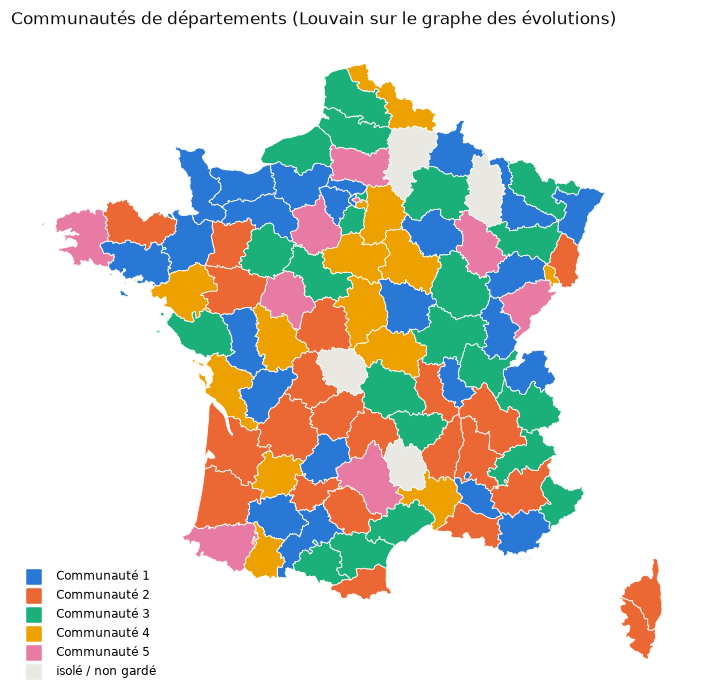

outre-mer : {'Guadeloupe': 2, 'Martinique': 5, 'Guyane': 'isolé', 'La Réunion': 'isolé'}


In [13]:
legende = [(f"Communauté {i}", gu.COULEURS[(i - 1) % len(gu.COULEURS)]) for i in range(1, len(communautes) + 1)]
legende.append(("isolé / non gardé", "#e9e8e3"))
gu.carte_departements(polys, lambda d: gu.COULEURS[(communaute[d] - 1) % len(gu.COULEURS)] if d in communaute else None,
                      "Communautés de départements (Louvain sur le graphe des évolutions)", legende=legende)
plt.show()
outre_mer = {nom(d): communaute.get(d, "isolé") for d in gu.DOM if d in S.index}
print("outre-mer :", outre_mer)

### Observations

- Sur la carte, on voit un **patchwork** de couleurs, ce qui confirme que les groupes ne sont pas géographiques.
- Outre-mer : la Guadeloupe est dans la communauté 2, la Martinique dans la communauté 5, la Guyane et La Réunion sont isolées.

## 9. Comment chaque communauté a-t-elle vécu les crises ?

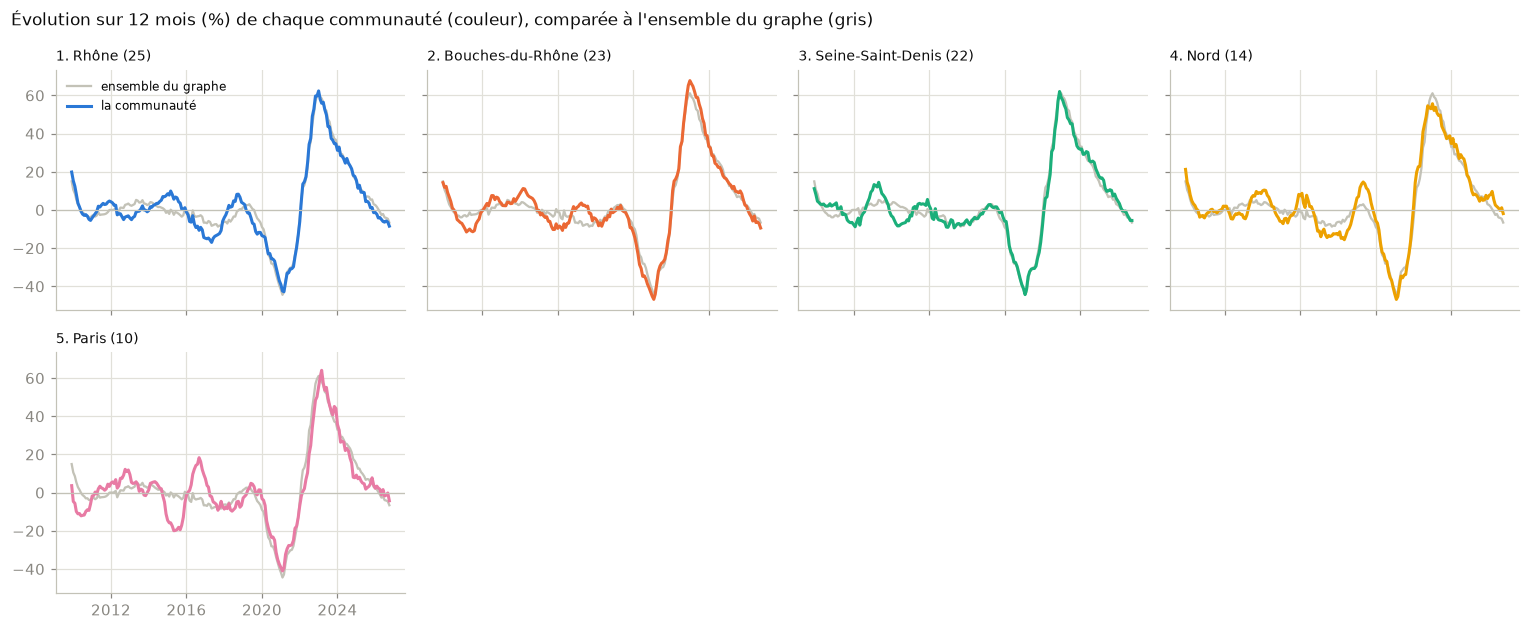

,départements,plus grand,creux Covid (%),pic du rattrapage (%),date du pic
communauté,,,,,
1,25,Rhône,-43.0,62.0,2023-01
2,23,Bouches-du-Rhône,-47.0,68.0,2023-01
3,22,Seine-Saint-Denis,-44.0,62.0,2022-12
4,14,Nord,-47.0,56.0,2023-01
5,10,Paris,-41.0,64.0,2023-03


In [14]:
nom_comm = lambda c: nom(max(c, key=lambda d: total[d]))
gu.tracer_evolution_communautes(evolution, communautes, nom_comm,
    "Évolution sur 12 mois (%) de chaque communauté (couleur), comparée à l'ensemble du graphe (gris)")
lignes = []
for i, c in enumerate(communautes, 1):
    e = 100 * evolution[sorted(c)].mean(axis=1)
    lignes.append({"communauté": i, "départements": len(c), "plus grand": nom_comm(c),
                   "creux Covid (%)": e.loc["2020-01":"2021-12"].min(),
                   "pic du rattrapage (%)": e.loc["2022-01":"2024-12"].max(),
                   "date du pic": e.loc["2022-01":"2024-12"].idxmax()})
resume = pd.DataFrame(lignes).set_index("communauté")
resume.round(0)

### Observations

- Les cinq communautés ont vécu le Covid de façon très proche (creux de **−41 % à −47 %**) et un rattrapage proche lui aussi (**+56 % à +68 %**). Les différences tiennent surtout au **calendrier** : le pic arrive en décembre 2022 pour la communauté 3 (Seine-Saint-Denis, Alpes-Maritimes, Hérault…), en mars 2023 pour la communauté 5 (Paris, Finistère, Oise…).

## 10. Visualisation du graphe et carte node2vec

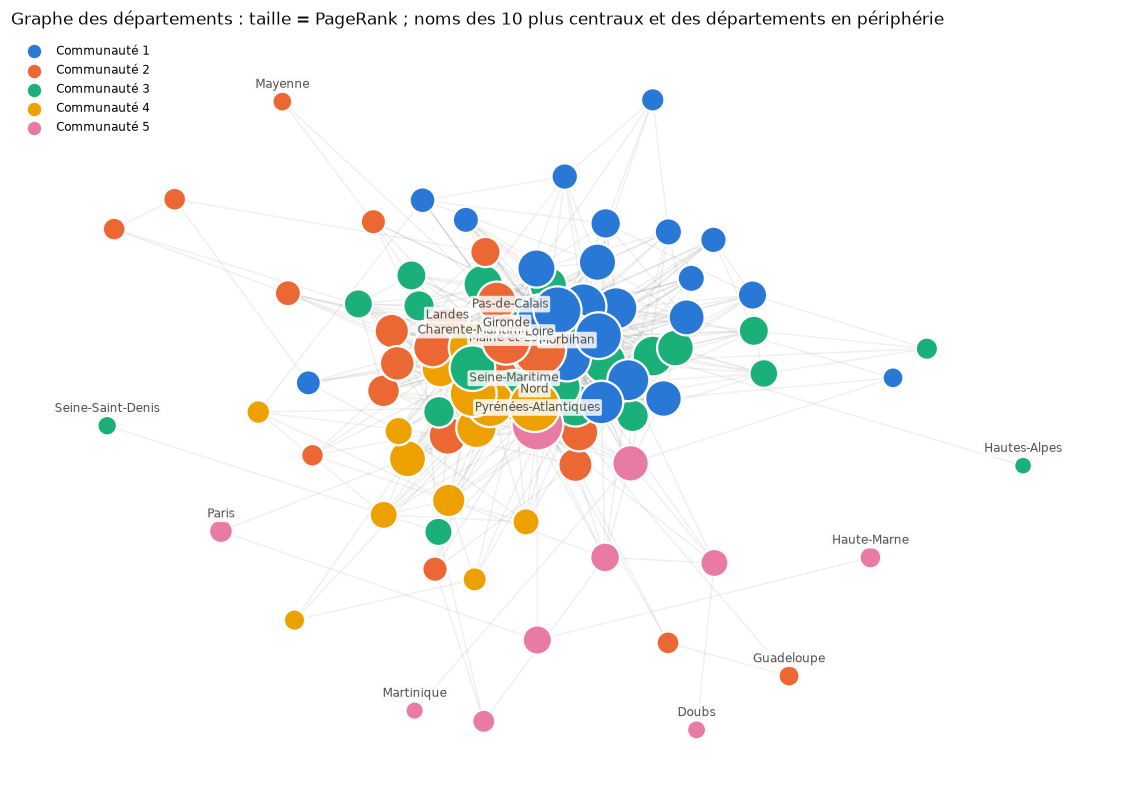

In [15]:
pos = nx.spring_layout(G, weight="weight", seed=0, k=0.5)
taille = 40 + 1200 * cent["pagerank"] / cent["pagerank"].max()
a_nommer = set(cent["pagerank"].nlargest(10).index) | set(cent.index[cent["degré"] <= 2])
gu.dessiner_graphe(G, pos, communaute, taille, a_nommer, nom,
                   "Graphe des départements : taille = PageRank ; noms des 10 plus centraux et des départements en périphérie")

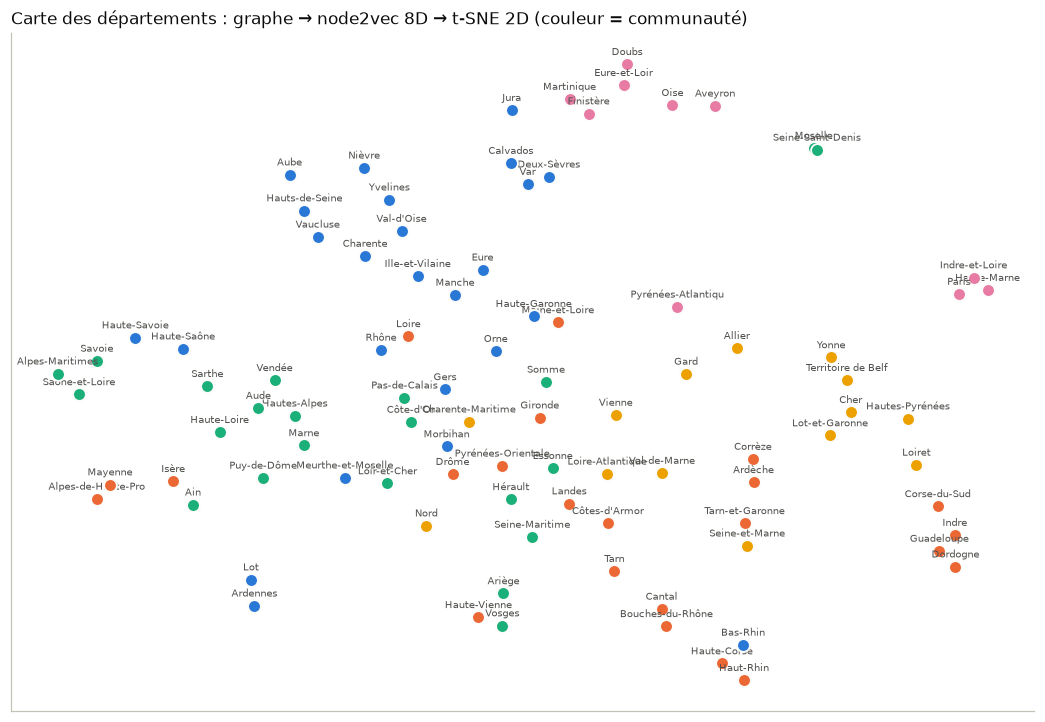

voisins sur la carte dans la même communauté : 0.59


In [16]:
noeuds, vecteurs, carte = gu.node2vec_tsne(G, perplexite=15)
fig, ax = plt.subplots(figsize=(12, 8))
for i, d in enumerate(noeuds):
    ax.scatter(*carte[i], s=70, color=gu.COULEURS[(communaute[d] - 1) % len(gu.COULEURS)],
               edgecolors="#fcfcfb", linewidths=1.2, zorder=3)
    ax.annotate(nom(d)[:18], carte[i], xytext=(0, 6), textcoords="offset points", ha="center", fontsize=6.5, color=gu.ENCRE)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Carte des départements : graphe → node2vec 8D → t-SNE 2D (couleur = communauté)", loc="left",
             fontsize=11, color=gu.TITRE)
plt.show()
print("voisins sur la carte dans la même communauté :",
      round(gu.accord_voisins(carte, [communaute[d] for d in noeuds]), 2))

### Observations

- Sur la carte node2vec + t-SNE, **59 %** des 3 plus proches voisins de chaque département sont dans la même communauté.

## 11. Export pour le dashboard

In [17]:
import shutil
noeuds_df = cent.copy()
noeuds_df.index.name = "departement"
noeuds_df["x_graphe"] = [pos[d][0] for d in noeuds_df.index]
noeuds_df["y_graphe"] = [pos[d][1] for d in noeuds_df.index]
noeuds_df = noeuds_df.join(pd.DataFrame(carte, index=noeuds, columns=["x_carte", "y_carte"])).reset_index()
aretes_df = pd.DataFrame([(u, v, d["weight"]) for u, v, d in G.edges(data=True)], columns=["source", "cible", "similarite"])
evo_comm = pd.DataFrame({f"Communauté {i}": evolution[sorted(c)].mean(axis=1) for i, c in enumerate(communautes, 1)})
evo_comm["Ensemble"] = evolution[list(G)].mean(axis=1)

noeuds_df.to_parquet(DASH / "graphe_departements_noeuds.parquet", index=False)
aretes_df.to_parquet(DASH / "graphe_departements_aretes.parquet", index=False)
evo_comm.to_parquet(DASH / "graphe_departements_evolution.parquet")
resume.reset_index().to_parquet(DASH / "graphe_departements_communautes.parquet", index=False)
shutil.copy(RAW / "geo" / "departements.geojson", DASH / "departements.geojson")
print(len(noeuds_df), "départements |", len(aretes_df), "arêtes |", evo_comm.shape)

94 départements | 869 arêtes | (203, 6)
